# Telco Customer Churn Analysis

## Project Overview

Customer churn refers to customers leaving a company's services.
The objective of this project is to analyze customer data, identify
patterns associated with churn, and provide actionable business
recommendations to improve customer retention.

## Objectives
- Analyze customer demographics and service usage.
- Identify factors associated with customer churn.
- Explore the relationship between tenure, charges, and churn.
- Calculate churn rates across different customer segments.
- Recommend strategies to reduce customer churn.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
churn = pd.read_csv('C:/Users/NIKITA/downloads/telco_customer.csv')

In [3]:
churn.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
churn.shape

(7043, 21)

In [5]:
churn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
churn.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


### Initial Data Understanding

The dataset contains customer demographic information, account details, subscribed services, billing information, and churn status.

These variables can be used to examine customer behavior and compare the characteristics of customers who left the company with those who remained.


In [7]:
churn.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
churn.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
7038    False
7039    False
7040    False
7041    False
7042    False
Length: 7043, dtype: bool

In [9]:
churn.duplicated().sum()

np.int64(0)

In [10]:
churn.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [11]:
churn["TotalCharges"] = pd.to_numeric(
    churn["TotalCharges"], errors="coerce"
)

In [12]:
churn["TotalCharges"].isnull().sum()

np.int64(11)

In [13]:
churn = churn.dropna(subset=["TotalCharges"])

### Data Cleaning

* Checked missing values across all columns.
* Identified duplicate records.
* Converted TotalCharges into a numeric data type.
* Reviewed missing TotalCharges values before deciding how to handle them.
* Verified data types after cleaning.

These steps help improve data quality and ensure reliable analysis.


In [14]:
churn.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 
 17  

In [15]:
for col in churn.columns:
    print(col, churn[col].nunique())

customerID 7032
gender 2
SeniorCitizen 2
Partner 2
Dependents 2
tenure 72
PhoneService 2
MultipleLines 3
InternetService 3
OnlineSecurity 3
OnlineBackup 3
DeviceProtection 3
TechSupport 3
StreamingTV 3
StreamingMovies 3
Contract 3
PaperlessBilling 2
PaymentMethod 4
MonthlyCharges 1584
TotalCharges 6530
Churn 2


In [16]:
churn["customerID"].nunique()

7032

In [17]:
churn["Churn"].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

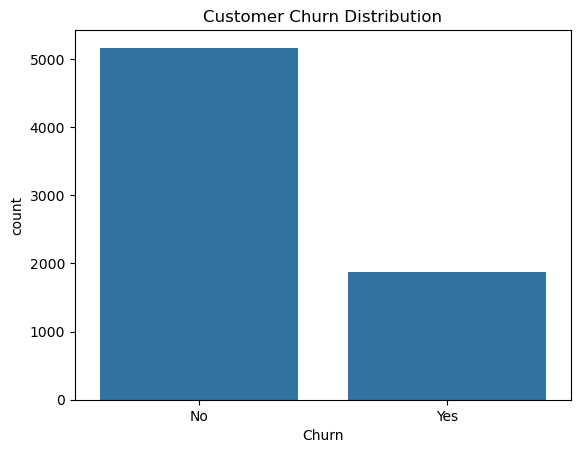

In [18]:
sns.countplot(data=churn, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

### Overall Churn Analysis

The overall churn rate represents the percentage of customers who left the company.

This metric provides a baseline for evaluating customer retention. The company can monitor this rate over time to determine whether retention initiatives are improving customer outcomes.

**Business Impact:** A high churn rate may indicate customer retention challenges and potential revenue risks.


In [19]:
churn_rate = (churn["Churn"] == "Yes").mean() * 100

print("Churn Rate:", round(churn_rate, 2), "%")

Churn Rate: 26.58 %


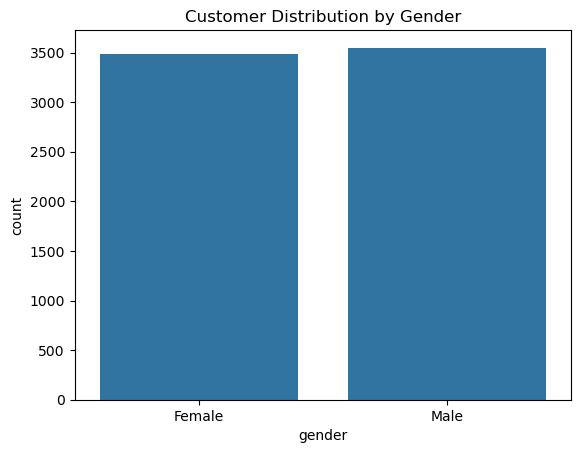

In [20]:
sns.countplot(data=churn, x="gender")
plt.title("Customer Distribution by Gender")
plt.show()

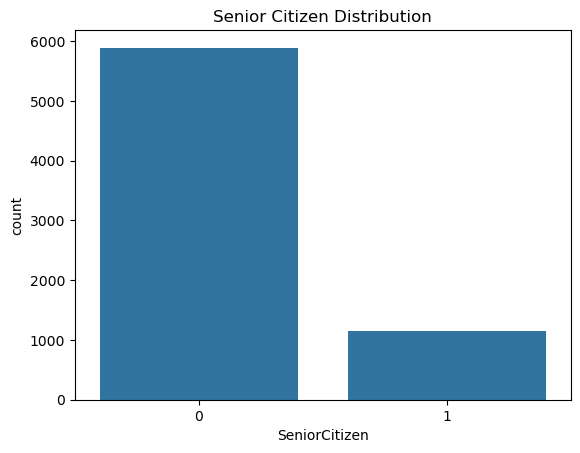

In [21]:
sns.countplot(data=churn, x="SeniorCitizen")
plt.title("Senior Citizen Distribution")
plt.show()

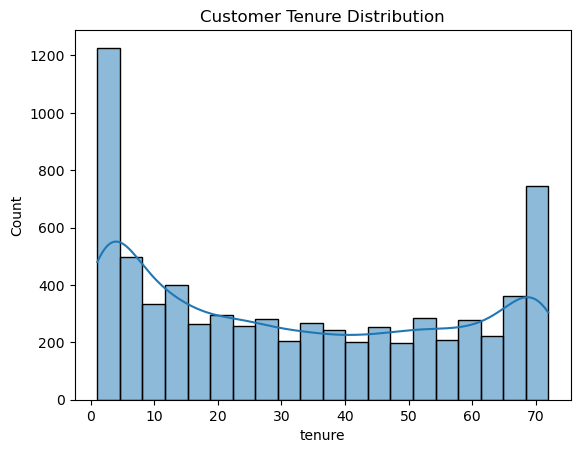

In [22]:
sns.histplot(data=churn, x="tenure", bins=20, kde=True)
plt.title("Customer Tenure Distribution")
plt.show()

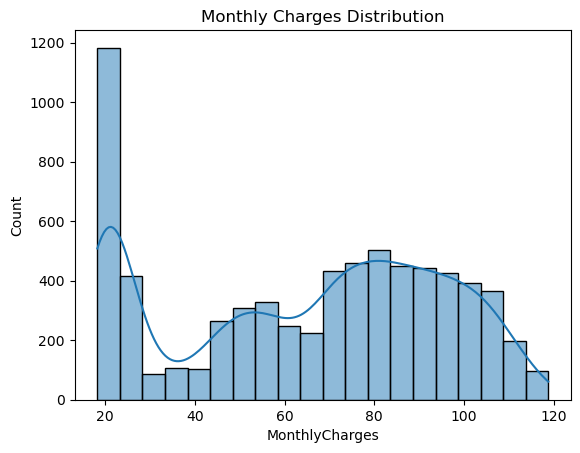

In [23]:
sns.histplot(data=churn, x="MonthlyCharges", bins=20, kde=True)
plt.title("Monthly Charges Distribution")
plt.show()

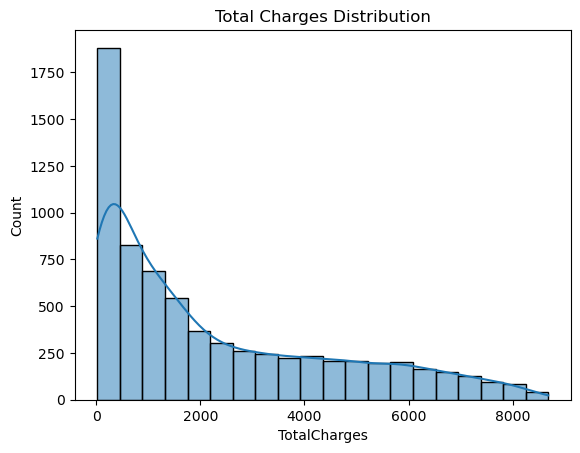

In [24]:
sns.histplot(data=churn, x="TotalCharges", bins=20, kde=True)
plt.title("Total Charges Distribution")
plt.show()

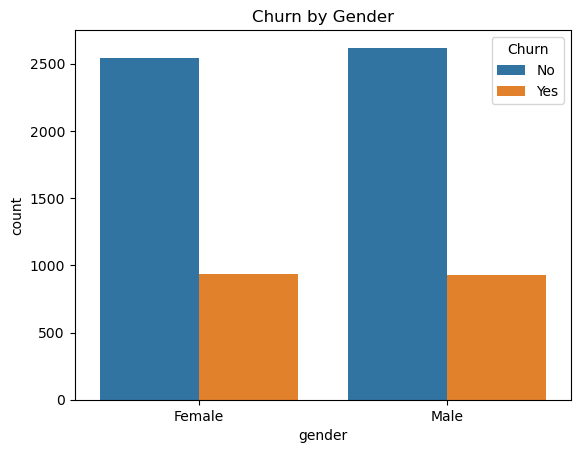

In [25]:
sns.countplot(data=churn, x="gender", hue="Churn")
plt.title("Churn by Gender")
plt.show()

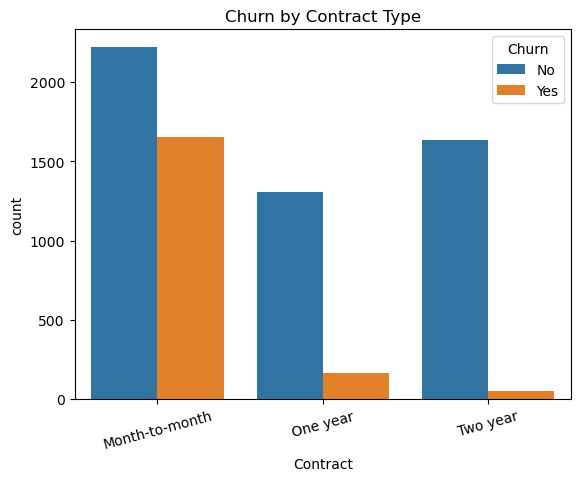

In [26]:
sns.countplot(data=churn, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xticks(rotation=15)
plt.show()

### Churn by Contract Type

Compared churn rates across month-to-month, one-year, and two-year contracts.

**Key Insight:** [Insert the contract type with the highest churn rate and its actual percentage.]

**Business Impact:** Contract categories with higher churn rates may represent customer segments that need additional retention attention.

**Recommendation:** Evaluate suitable renewal incentives and customer engagement strategies for the affected segments.


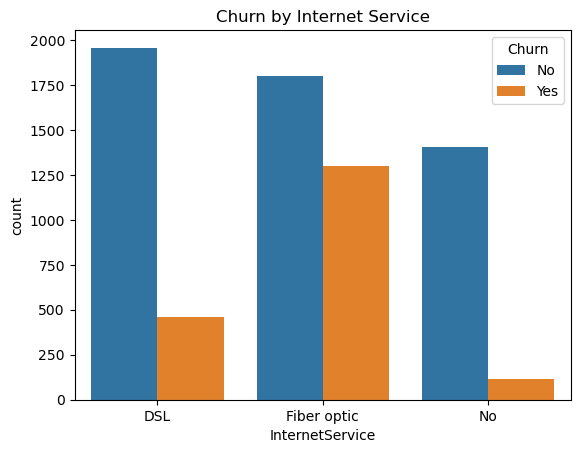

In [27]:
sns.countplot(data=churn, x="InternetService", hue="Churn")
plt.title("Churn by Internet Service")
plt.show()

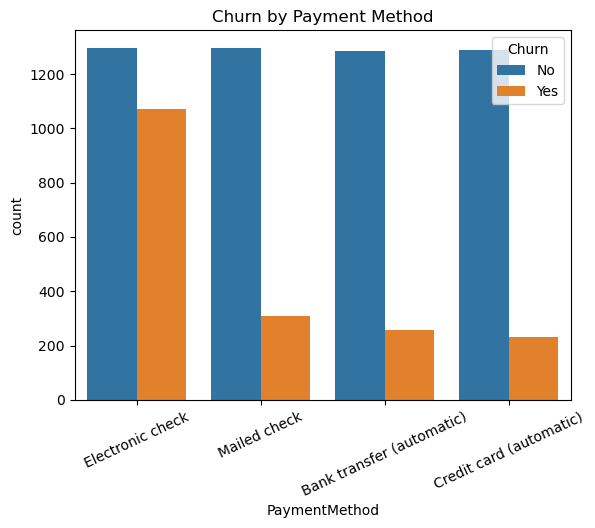

In [28]:
sns.countplot(data=churn, x="PaymentMethod", hue="Churn")
plt.title("Churn by Payment Method")
plt.xticks(rotation=25)
plt.show()

### Insight: Churn by Payment Method

- Electronic check customers show the highest churn rate in the plotted results.
- Other payment methods show comparatively lower churn rates.
- The company should investigate payment-related customer
  concerns and offer convenient payment options.

**Recommendation:** Encourage convenient payment methods and
monitor churn among electronic check users.

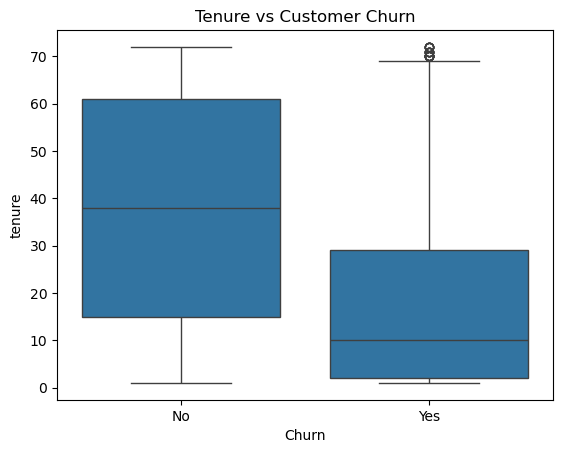

In [29]:
sns.boxplot(data=churn, x="Churn", y="tenure")
plt.title("Tenure vs Customer Churn")
plt.show()

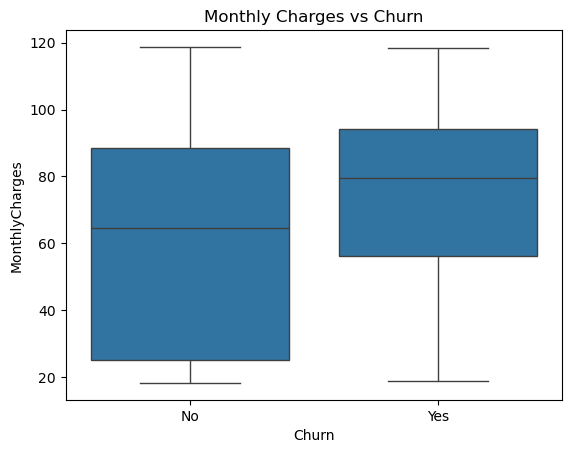

In [30]:
sns.boxplot(data=churn, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.show()

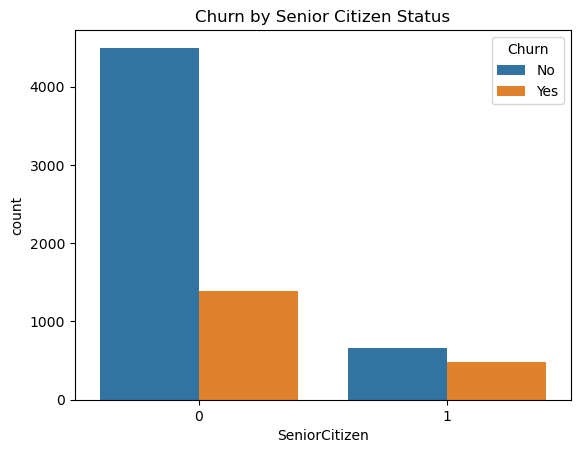

In [31]:
sns.countplot(data=churn, x="SeniorCitizen", hue="Churn")
plt.title("Churn by Senior Citizen Status")
plt.show()

In [32]:
internet_churn = pd.crosstab(
    churn["InternetService"],
    churn["Churn"],
    normalize="index"
) * 100

print(internet_churn)

Churn                   No        Yes
InternetService                      
DSL              81.001656  18.998344
Fiber optic      58.107235  41.892765
No               92.565789   7.434211


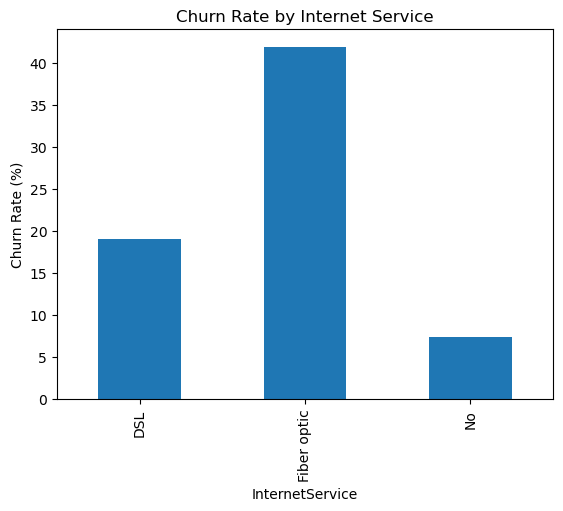

In [33]:
internet_churn["Yes"].plot(
    kind="bar",
    title="Churn Rate by Internet Service"
)

plt.ylabel("Churn Rate (%)")
plt.show()

In [34]:
payment_churn = pd.crosstab(
    churn["PaymentMethod"],
    churn["Churn"],
    normalize="index"
) * 100

print(payment_churn)

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.268482  16.731518
Credit card (automatic)    84.746877  15.253123
Electronic check           54.714588  45.285412
Mailed check               80.798005  19.201995


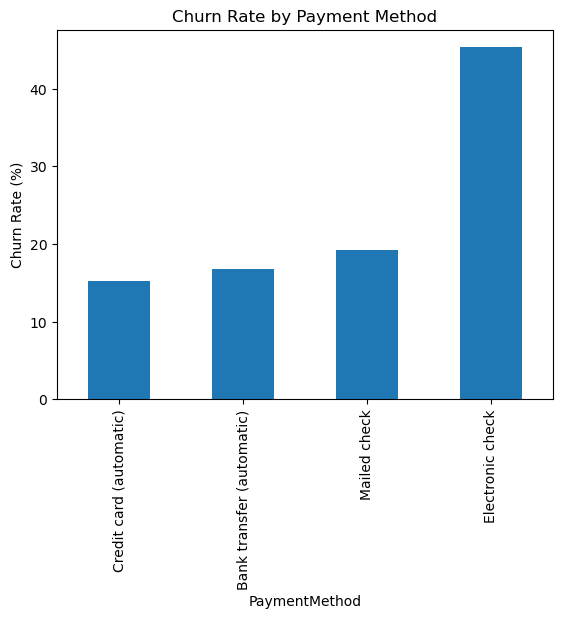

In [35]:
payment_churn["Yes"].sort_values().plot(
    kind="bar",
    title="Churn Rate by Payment Method"
)

plt.ylabel("Churn Rate (%)")
plt.show()

In [36]:
numeric_df = churn[
    ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
]

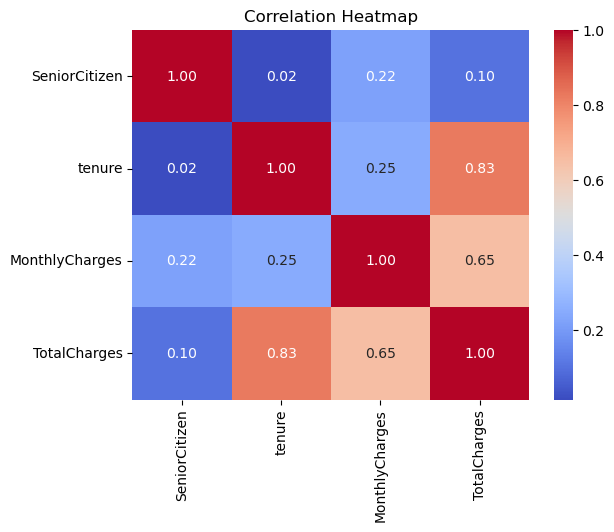

In [37]:
sns.heatmap(numeric_df.corr(),annot=True,cmap="coolwarm",fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

### Insight: Correlation Analysis

- Tenure and TotalCharges have a strong positive correlation (0.83).
- MonthlyCharges and TotalCharges have a positive correlation (0.65).
- SeniorCitizen has relatively weak correlations with the other
  numerical variables shown.
- Correlation indicates association, not causation.

**Recommendation:** Consider tenure and monthly charges together
when analyzing customer behavior.

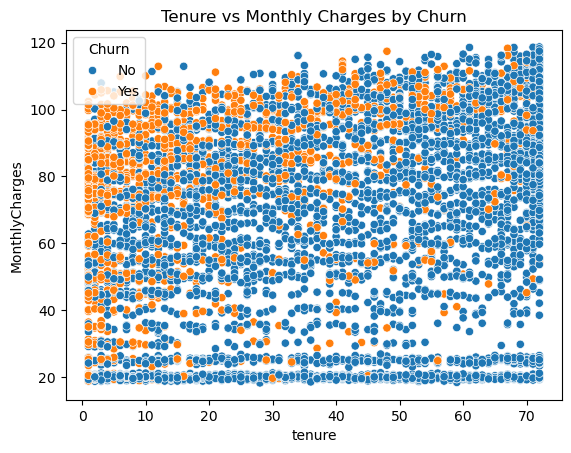

In [38]:
sns.scatterplot(data=churn,x="tenure",y="MonthlyCharges",hue="Churn")

plt.title("Tenure vs Monthly Charges by Churn")
plt.show()

### Insight: Tenure vs Monthly Charges

- Customers who churn are visible across different monthly-charge
  levels and tenure periods.
- Monthly charges alone may not explain customer churn.
- Tenure should be analyzed alongside contract type and services.

**Recommendation:** Identify new customers who may need additional
support during their initial months.

In [39]:
churn["TenureGroup"] = pd.cut(churn["tenure"],bins=[-1, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months",
            "25-48 Months", "49-72 Months"]
)

In [40]:
tenure_churn = pd.crosstab(
    churn["TenureGroup"],
    churn["Churn"],
    normalize="index"
) * 100

print(tenure_churn)

Churn                No        Yes
TenureGroup                       
0-12 Months   52.321839  47.678161
13-24 Months  71.289062  28.710938
25-48 Months  79.611041  20.388959
49-72 Months  90.486824   9.513176


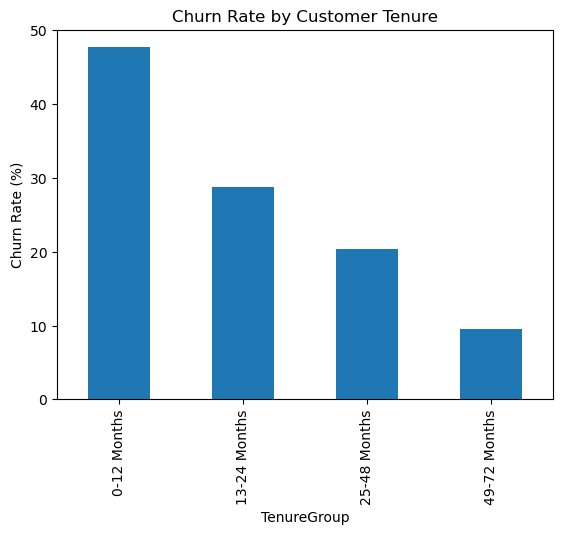

In [41]:
tenure_churn["Yes"].plot(
    kind="bar",
    title="Churn Rate by Customer Tenure"
)

plt.ylabel("Churn Rate (%)")
plt.show()

### Insight: Churn by Customer Tenure

- Customers with 0–12 months of tenure have a churn rate of 47.68%.
- The churn rate decreases across the longer-tenure groups.
- Customers with 49–72 months of tenure have a churn rate of 9.51%.

**Recommendation:** Focus retention campaigns on customers during
their first year.

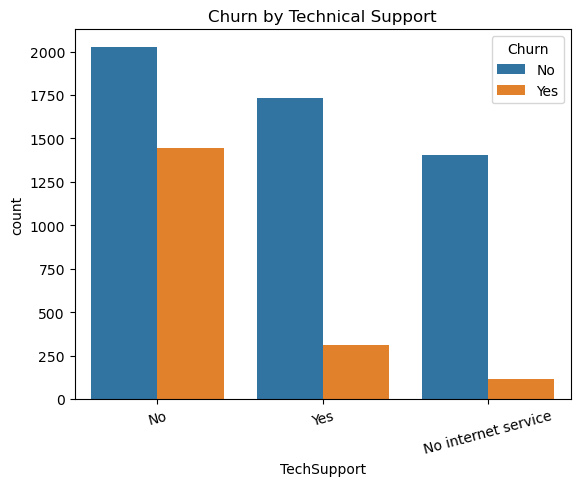

In [42]:
sns.countplot(data=churn, x="TechSupport", hue="Churn")

plt.title("Churn by Technical Support")
plt.xticks(rotation=15)
plt.show()

### Insight: Churn by Technical Support

- The countplot shows more churned customers in the group without
  technical support than in the group receiving support.
- The chart displays customer counts, not churn percentages.
- A rate-based comparison is needed to account for differences
  in group sizes.

**Recommendation:** Investigate support needs and improve access
to technical assistance.

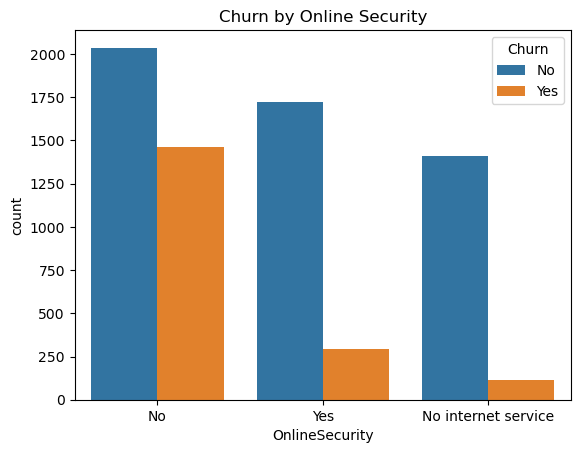

In [43]:
sns.countplot(data=churn, x="OnlineSecurity", hue="Churn")

plt.title("Churn by Online Security")
plt.show()

### Insight: Churn by Online Security

- The countplot shows a larger number of churned customers among
  customers without online security.
- Customer counts alone do not establish the exact churn rate.
- Compare the churn percentages of each category before drawing
  a final conclusion.

**Recommendation:** Review security-service needs and communicate
the benefits of available security plans.

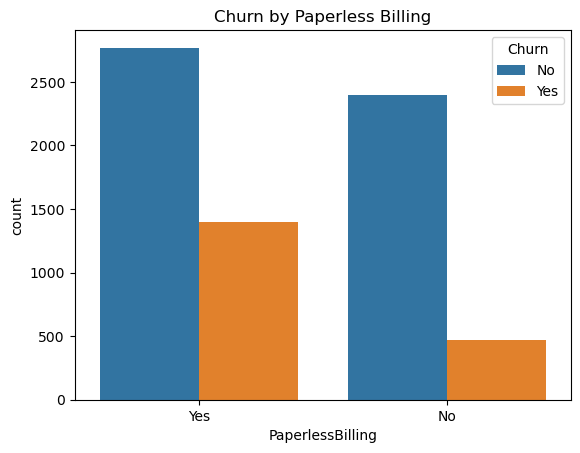

In [44]:
sns.countplot(data=churn, x="PaperlessBilling", hue="Churn")

plt.title("Churn by Paperless Billing")
plt.show()

### Insight: Churn by Paperless Billing

- The countplot shows churned and retained customer counts for
  paperless and non-paperless billing groups.
- Counts do not directly represent the churn rate of each group.
- Further analysis is needed to determine the percentage of
  customers churning in each category.

**Recommendation:** Compare actual churn rates before deciding
whether billing preferences are associated with churn.

In [45]:
churn.groupby("Contract")["MonthlyCharges"].mean().round(2)

Contract
Month-to-month    66.40
One year          65.08
Two year          60.87
Name: MonthlyCharges, dtype: float64

### Insight: Churn by Contract Type

- Month-to-month customers have the highest churn rate (42.71%).
- One-year contract customers have a churn rate of 11.28%.
- Two-year contract customers have the lowest churn rate (2.85%).

**Recommendation:** Offer suitable long-term contract incentives
and prioritize retention efforts for month-to-month customers.

In [46]:
churn.groupby("Churn")["tenure"].mean().round(2)

Churn
No     37.65
Yes    17.98
Name: tenure, dtype: float64

### Insight: Average Tenure by Churn

- Customers who churn have an average tenure of 17.98 months.
- Customers who stay have an average tenure of 37.65 months.
- Churned customers have a substantially shorter average tenure.

**Recommendation:** Strengthen onboarding and engagement during
the early stages of the customer relationship.

In [47]:
churn.groupby("Churn")["TotalCharges"].mean().round(2)

Churn
No     2555.34
Yes    1531.80
Name: TotalCharges, dtype: float64

### Insight: Average Total Charges by Churn

- Customers who stay have higher average TotalCharges (2555.34).
- Customers who churn have lower average TotalCharges (1531.80).
- TotalCharges are influenced by factors such as tenure and
  monthly charges, so this difference should not be interpreted
  as proof of a direct cause of churn.

**Recommendation:** Evaluate tenure and monthly charges together
when identifying customers who may be at risk of churning.

In [48]:
pd.crosstab(churn["Contract"], churn["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48


### Insight: Contract-wise Customer Distribution

- Month-to-month contracts have the largest number of churned customers.
- One-year and two-year contracts have substantially fewer churned customers.
- The distribution supports further investigation of contract type
  as a factor associated with churn.

**Recommendation:** Prioritize month-to-month customers for retention
campaigns and evaluate incentives for longer contracts.

In [49]:
churn.groupby("Churn")["MonthlyCharges"].sum().round(2)

Churn
No     316530.15
Yes    139130.85
Name: MonthlyCharges, dtype: float64

In [50]:
factors = ["Contract","InternetService","PaymentMethod","TechSupport","OnlineSecurity","PaperlessBilling"]

for col in factors:
    print("\nChurn Rate by", col)

    print(
        churn.groupby(col, observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .round(2)
        .sort_values(ascending=False)
    )


Churn Rate by Contract
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn, dtype: float64

Churn Rate by InternetService
InternetService
Fiber optic    41.89
DSL            19.00
No              7.43
Name: Churn, dtype: float64

Churn Rate by PaymentMethod
PaymentMethod
Electronic check             45.29
Mailed check                 19.20
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Name: Churn, dtype: float64

Churn Rate by TechSupport
TechSupport
No                     41.65
Yes                    15.20
No internet service     7.43
Name: Churn, dtype: float64

Churn Rate by OnlineSecurity
OnlineSecurity
No                     41.78
Yes                    14.64
No internet service     7.43
Name: Churn, dtype: float64

Churn Rate by PaperlessBilling
PaperlessBilling
Yes    33.59
No     16.38
Name: Churn, dtype: float64


# Final Conclusion

The exploratory data analysis identified several patterns
associated with customer churn.

## Key Findings

1. Month-to-month customers have a churn rate of 42.71%.
2. Fiber optic customers have a churn rate of 41.89%.
3. Customers with 0–12 months of tenure have a churn rate of 47.68%.
4. Two-year contract customers have a churn rate of only 2.85%.
5. Customers who churn have a lower average tenure than customers
   who stay.

## Business Recommendations

- Focus on retaining customers during their first year.
- Offer suitable incentives for long-term contracts.
- Investigate fiber optic pricing and service quality.
- Improve customer support and communicate service benefits.
- Identify high-risk customer segments using churn-rate analysis.
- Monitor retention campaign results to measure improvement.

## Project Outcome

This analysis helps identify customer segments associated
with higher churn and provides actionable recommendations
to support customer retention.

Note: These findings are based on exploratory analysis and
show associations, not necessarily causal relationships.